<a href="https://colab.research.google.com/github/RiccoFlores/Python/blob/master/WalkIN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# 1. Upload the file
df_GC = pd.read_csv('GuestCenter.csv')
df_GC.head()

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Visit Date,Visit Time,Seated Date,Finished Date,Size,Table,Source
0,21/11/2026,15:00,21/11/2026 14:45,NaN,2,32,Your Network
1,21/11/2026,15:00,21/11/2026 14:45,NaN,2,23,Your Network
2,21/11/2026,15:00,21/11/2026 14:49,NaN,6,24,Phone/In-house
3,21/11/2026,14:49,21/11/2026 14:49,NaN,5,40,Walk-in
4,21/11/2026,14:49,21/11/2026 14:49,NaN,2,42,Walk-in


In [9]:
# 2. Numeric Summary
df_GC.describe(include="all")


,Visit Date,Visit Time,Seated Date,Finished Date,Size,Table,Source
count,13919,13919,13919,9548,13919.000000,13919,13919
unique,320,354,10642,4898,NaN,145,4
top,25/07/2026,13:00,28/03/2026 15:14,17/07/2026 17:29,NaN,34,Walk-in
freq,112,1561,17,35,NaN,569,6644
mean,NaN,NaN,NaN,NaN,2.706947,NaN,NaN
std,NaN,NaN,NaN,NaN,1.906788,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,2.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,3.000000,NaN,NaN


In [10]:
# 2.1 Data Understanding, let's clarify our categories in column Source
print("Booking Sources:\n", df_GC['Source'].value_counts(dropna=False))


Booking Sources:
 Source
Walk-in              6644
Your Network         4489
OpenTable Network    1737
Phone/In-house       1049
Name: count, dtype: int64


In [11]:
# 2.2 Data Understanding, let's check if we are with an actual DATE format
df_GC.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13919 entries, 0 to 13918
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Visit Date     13919 non-null  object
 1   Visit Time     13919 non-null  object
 2   Seated Date    13919 non-null  object
 3   Finished Date  9548 non-null   object
 4   Size           13919 non-null  int64 
 5   Table          13919 non-null  object
 6   Source         13919 non-null  object
dtypes: int64(1), object(6)
memory usage: 761.3+ KB


In [12]:
# 3. Parse Seated Date and Finished Date (dayfirst=True handles DD/MM/YYYY safely)
df_GC['Seated Date'] = pd.to_datetime(df_GC['Seated Date'], dayfirst=True, errors='coerce')
df_GC['Finished Date'] = pd.to_datetime(df_GC['Finished Date'], dayfirst=True, errors='coerce')

# 3.1 Extract pure date string from Visit Date and pure time string from Visit Time
visit_date_str = pd.to_datetime(df_GC['Visit Date'], dayfirst=True, errors='coerce').dt.strftime('%Y-%m-%d')

In [13]:
# 3.1 Handle Visit Time whether Excel stored it as datetime.time, full datetime, or text
def extract_time_str(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    # If Excel attached a dummy date like '1899-12-30 13:30:00', keep only the time portion
    if ' ' in val_str:
        return val_str.split(' ')[-1]
    return val_str

visit_time_str = df_GC['Visit Time'].apply(extract_time_str)

In [14]:
# 3.2 Merge into 'Booking Date and Time'
df_GC['Booking Date and Time'] = pd.to_datetime(
    visit_date_str + ' ' + visit_time_str,
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)

# Fallback if Visit Time had HH:MM without seconds
mask_nat = df_GC['Booking Date and Time'].isna() & visit_date_str.notna() & visit_time_str.notna()
df_GC.loc[mask_nat, 'Booking Date and Time'] = pd.to_datetime(
    visit_date_str[mask_nat] + ' ' + visit_time_str[mask_nat],
    errors='coerce'
)

# Verify the new column and null counts
display(df_GC[['Visit Date', 'Visit Time', 'Booking Date and Time', 'Seated Date', 'Finished Date']].head())
print("\nNull counts after parsing:")
print(df_GC[['Booking Date and Time', 'Seated Date', 'Finished Date']].isna().sum())

,Visit Date,Visit Time,Booking Date and Time,Seated Date,Finished Date
0,21/11/2026,15:00,2026-11-21 15:00:00,2026-11-21 14:45:00,NaT
1,21/11/2026,15:00,2026-11-21 15:00:00,2026-11-21 14:45:00,NaT
2,21/11/2026,15:00,2026-11-21 15:00:00,2026-11-21 14:49:00,NaT
3,21/11/2026,14:49,2026-11-21 14:49:00,2026-11-21 14:49:00,NaT
4,21/11/2026,14:49,2026-11-21 14:49:00,2026-11-21 14:49:00,NaT



Null counts after parsing:
Booking Date and Time       0
Seated Date                 0
Finished Date            4371
dtype: int64


In [15]:
df_GC.head()

,Visit Date,Visit Time,Seated Date,Finished Date,Size,Table,Source,Booking Date and Time
0,21/11/2026,15:00,2026-11-21 14:45:00,NaT,2,32,Your Network,2026-11-21 15:00:00
1,21/11/2026,15:00,2026-11-21 14:45:00,NaT,2,23,Your Network,2026-11-21 15:00:00
2,21/11/2026,15:00,2026-11-21 14:49:00,NaT,6,24,Phone/In-house,2026-11-21 15:00:00
3,21/11/2026,14:49,2026-11-21 14:49:00,NaT,5,40,Walk-in,2026-11-21 14:49:00
4,21/11/2026,14:49,2026-11-21 14:49:00,NaT,2,42,Walk-in,2026-11-21 14:49:00


In [16]:
# 4. Some data cleaning
# Remove the original 'Visit Date' and 'Visit Time' columns
df_GC = df_GC.drop(columns=['Visit Date', 'Visit Time'], errors='ignore')

# 4.1 Move 'Booking Date and Time' to the first position
cols = ['Booking Date and Time'] + [col for col in df_GC.columns if col != 'Booking Date and Time']
df_GC = df_GC[cols]

print("Updated columns:", df_GC.columns.tolist())
display(df_GC.head())

Updated columns: ['Booking Date and Time', 'Seated Date', 'Finished Date', 'Size', 'Table', 'Source']


,Booking Date and Time,Seated Date,Finished Date,Size,Table,Source
0,2026-11-21 15:00:00,2026-11-21 14:45:00,NaT,2,32,Your Network
1,2026-11-21 15:00:00,2026-11-21 14:45:00,NaT,2,23,Your Network
2,2026-11-21 15:00:00,2026-11-21 14:49:00,NaT,6,24,Phone/In-house
3,2026-11-21 14:49:00,2026-11-21 14:49:00,NaT,5,40,Walk-in
4,2026-11-21 14:49:00,2026-11-21 14:49:00,NaT,2,42,Walk-in


In [17]:
# 5. Calculate durations in minutes for valid, non-null rows
df_GC['wait_minutes'] = (df_GC['Seated Date'] - df_GC['Booking Date and Time']).dt.total_seconds() / 60
df_GC['dwell_minutes'] = (df_GC['Finished Date'] - df_GC['Seated Date']).dt.total_seconds() / 60

# Filter valid dwell times (e.g., between 10 mins and 360 mins / 6 hours) to avoid unclosed-till outliers
valid_dwell = df_GC[(df_GC['dwell_minutes'] >= 10) & (df_GC['dwell_minutes'] <= 360)]

mean_dwell = valid_dwell['dwell_minutes'].mean()
median_dwell = valid_dwell['dwell_minutes'].median()

print(f"Valid completed sittings analyzed: {len(valid_dwell)}")
print(f"Average table time in use (Mean):   {mean_dwell:.1f} minutes ({mean_dwell/60:.2f} hours)")
print(f"Median table time in use (Median):  {median_dwell:.1f} minutes ({median_dwell/60:.2f} hours)")

# Check how dwell time varies by party Size (optional check)
print("\nAverage Dwell Time (mins) by Party Size:")
display(valid_dwell.groupby('Size')['dwell_minutes'].agg(['count', 'mean', 'median']).round(1))

Valid completed sittings analyzed: 8880
Average table time in use (Mean):   97.2 minutes (1.62 hours)
Median table time in use (Median):  86.0 minutes (1.43 hours)

Average Dwell Time (mins) by Party Size:


,count,mean,median
Size,,,
1,830,75.5,62.0
2,4984,94.5,83.0
3,1408,106.6,98.0
4,969,105.1,97.0
5,323,107.1,102.0
6,174,112.2,105.0
7,49,119.9,109.0
8,38,131.8,122.0
9,17,117.4,106.0


In [19]:
# Data imputation. Create a flag so you always know which Finished Dates were imputed
df_GC['Finished_Date_Imputed'] = df_GC['Finished Date'].isna() & df_GC['Seated Date'].notna()

# Option A: Impute using the overall mean dwell time
df_GC.loc[df_GC['Finished_Date_Imputed'], 'Finished Date'] = (
    df_GC.loc[df_GC['Finished_Date_Imputed'], 'Seated Date'] + pd.to_timedelta(mean_dwell, unit='m')
)


print(f"Imputed {df_GC['Finished_Date_Imputed'].sum()} missing Finished Date records.")
print("Remaining nulls in Finished Date (rows never seated):", df_GC['Finished Date'].isna().sum())

Imputed 0 missing Finished Date records.
Remaining nulls in Finished Date (rows never seated): 0


In [20]:
display(df_GC.head())

,Booking Date and Time,Seated Date,Finished Date,Size,Table,Source,wait_minutes,dwell_minutes,Finished_Date_Imputed
0,2026-11-21 15:00:00,2026-11-21 14:45:00,2026-11-21 16:22:11.168918916,2,32,Your Network,-15.0,NaN,False
1,2026-11-21 15:00:00,2026-11-21 14:45:00,2026-11-21 16:22:11.168918916,2,23,Your Network,-15.0,NaN,False
2,2026-11-21 15:00:00,2026-11-21 14:49:00,2026-11-21 16:26:11.168918916,6,24,Phone/In-house,-11.0,NaN,False
3,2026-11-21 14:49:00,2026-11-21 14:49:00,2026-11-21 16:26:11.168918916,5,40,Walk-in,0.0,NaN,False
4,2026-11-21 14:49:00,2026-11-21 14:49:00,2026-11-21 16:26:11.168918916,2,42,Walk-in,0.0,NaN,False


In [21]:
# 6. Recover the true imputation flag before recalculating dwell_minutes
# (Rows where Finished Date is now populated, but original dwell_minutes was NaN)
df_GC['Was_Imputed'] = df_GC['Finished_Date_Imputed'] | (
    df_GC['Finished Date'].notna() & df_GC['dwell_minutes'].isna()
)

# 6.1 Recalculate dwell_minutes across all rows now that Finished Date is filled
df_GC['dwell_minutes'] = (df_GC['Finished Date'] - df_GC['Seated Date']).dt.total_seconds() / 60

# 6.2 Inspect all booking sources and create Visit_Type ('Walk-in' vs 'Booking')
print("=== Booking Sources in df_GC ===")
print(df_GC['Source'].value_counts(dropna=False))

df_GC['Visit_Type'] = np.where(
    df_GC['Source'].astype(str).str.strip().str.lower() == 'walk-in',
    'Walk-in',
    'Booking'
)

print(f"\nRecovered imputed rows: {df_GC['Was_Imputed'].sum()}")
print(f"Observed (non-imputed) finished rows: {(~df_GC['Was_Imputed'] & df_GC['Finished Date'].notna()).sum()}")

=== Booking Sources in df_GC ===
Source
Walk-in              6644
Your Network         4489
OpenTable Network    1737
Phone/In-house       1049
Name: count, dtype: int64

Recovered imputed rows: 4371
Observed (non-imputed) finished rows: 9548


In [22]:
# 7. Filter for seated walk-ins
walkins_df = df_GC[(df_GC['Visit_Type'] == 'Walk-in') & (df_GC['Seated Date'].notna())].copy()
walkins_df['Date'] = walkins_df['Seated Date'].dt.normalize()
walkins_df['Size'] = pd.to_numeric(walkins_df['Size'], errors='coerce')

# 7.1 Aggregate walk-in parties and covers (guests) per day
daily_walkins = (
    walkins_df.groupby('Date')
    .agg(
        walkin_parties=('Visit_Type', 'count'),
        walkin_guests=('Size', 'sum'),
        avg_party_size=('Size', 'mean')
    )
    .reset_index()
)

# 7.2 Reindex against all active operating dates in df_GC so 0-walk-in open days count as 0,
# while closed days (e.g., museum/restaurant closure days) do not drag down averages
operating_dates = pd.Series(df_GC['Seated Date'].dropna().dt.normalize().unique()).sort_values()

daily_walkins = (
    daily_walkins.set_index('Date')
    .reindex(operating_dates, fill_value=0)
    .rename_axis('Date')
    .reset_index()
)

daily_walkins['Day_of_Week'] = daily_walkins['Date'].dt.day_name()
daily_walkins['Month'] = daily_walkins['Date'].dt.to_period('M').astype(str)

# 7.3 Overall summary
print(f"Total operating days analyzed: {len(daily_walkins)}")
print("\n=== Overall Daily Walk-In Summary ===")
display(daily_walkins[['walkin_parties', 'walkin_guests', 'avg_party_size']].describe().round(2))

# 7. Breakdown by Day of the Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_summary = (
    daily_walkins.groupby('Day_of_Week')
    .agg(
        open_days=('Date', 'count'),
        mean_parties=('walkin_parties', 'mean'),
        sd_parties=('walkin_parties', 'std'),
        median_parties=('walkin_parties', 'median'),
        iqr_parties=('walkin_parties', lambda x: x.quantile(0.75) - x.quantile(0.25)),
        mean_guests=('walkin_guests', 'mean'),
        median_guests=('walkin_guests', 'median')
    )
    .reindex(day_order)
    .round(2)
)

print("\n=== Daily Walk-Ins by Day of Week ===")
display(dow_summary)

Total operating days analyzed: 320

=== Overall Daily Walk-In Summary ===


,walkin_parties,walkin_guests,avg_party_size
count,320.00,320.00,320.00
mean,20.76,48.22,2.30
std,12.03,29.22,0.33
min,3.00,5.00,1.44
25%,12.00,26.75,2.09
50%,19.00,45.00,2.29
75%,27.00,62.00,2.48
max,71.00,171.00,3.72



=== Daily Walk-Ins by Day of Week ===


,open_days,mean_parties,sd_parties,median_parties,iqr_parties,mean_guests,median_guests
Day_of_Week,,,,,,,
Monday,46,19.24,10.77,18.0,14.50,45.70,41.5
Tuesday,45,18.89,10.55,17.0,16.00,41.71,35.0
Wednesday,45,17.27,9.27,16.0,11.00,39.73,34.0
Thursday,46,16.63,7.98,15.5,10.75,37.91,33.0
Friday,46,19.24,12.32,16.0,12.75,43.76,38.0
Saturday,47,26.77,14.27,24.0,12.00,64.87,59.0
Sunday,45,27.20,13.40,26.0,13.00,63.51,58.0


In [23]:
from scipy import stats

# 1. Filter to genuine (non-imputed) dwell durations within valid bounds (10–360 mins)
observed_df = df_GC[
    (~df_GC['Was_Imputed']) &
    (df_GC['dwell_minutes'] >= 10) &
    (df_GC['dwell_minutes'] <= 360)
].copy()

# 2. Summary statistics by Visit_Type
duration_stats = (
    observed_df.groupby('Visit_Type')['dwell_minutes']
    .agg(
        observed_tables='count',
        mean_mins='mean',
        sd_mins='std',
        median_mins='median',
        iqr_mins=lambda x: x.quantile(0.75) - x.quantile(0.25),
        p90_mins=lambda x: x.quantile(0.90)
    )
    .round(1)
)

print("=== Table Dwell Duration (Minutes): Walk-In vs. Booking (Observed Only) ===")
display(duration_stats)

# 3. Statistical significance tests
walk_dur = observed_df.loc[observed_df['Visit_Type'] == 'Walk-in', 'dwell_minutes']
book_dur = observed_df.loc[observed_df['Visit_Type'] == 'Booking', 'dwell_minutes']

u_stat, p_mw = stats.mannwhitneyu(walk_dur, book_dur, alternative='two-sided')
t_stat, p_t = stats.ttest_ind(walk_dur, book_dur, equal_var=False)

print(f"\nMean Difference (Walk-in - Booking):   {walk_dur.mean() - book_dur.mean():+.1f} mins (Welch's t p = {p_t:.4e})")
print(f"Median Difference (Walk-in - Booking): {walk_dur.median() - book_dur.median():+.1f} mins (Mann-Whitney p = {p_mw:.4e})")

# 4. Control for Party Size (to check if walk-ins are shorter simply because parties are smaller)
size_dwell = (
    observed_df[observed_df['Size'].between(1, 6)]
    .groupby(['Size', 'Visit_Type'])['dwell_minutes']
    .agg(count='count', mean_mins='mean', median_mins='median')
    .unstack()
    .round(1)
)
print("\n=== Dwell Duration by Party Size (1–6 Guests) ===")
display(size_dwell)

=== Table Dwell Duration (Minutes): Walk-In vs. Booking (Observed Only) ===


,observed_tables,mean_mins,sd_mins,median_mins,iqr_mins,p90_mins
Visit_Type,,,,,,
Booking,4555,111.4,57.7,102.0,68.0,185.6
Walk-in,4325,82.2,55.4,68.0,62.0,154.0



Mean Difference (Walk-in - Booking):   -29.3 mins (Welch's t p = 2.8519e-127)
Median Difference (Walk-in - Booking): -34.0 mins (Mann-Whitney p = 1.1335e-177)

=== Dwell Duration by Party Size (1–6 Guests) ===


count         mean_mins         median_mins        
Visit_Type Booking Walk-in   Booking Walk-in     Booking Walk-in
Size                                                            
1              161     669      88.9    72.3        79.0    58.0
2             2382    2602     107.2    82.9        96.0    69.0
3              903     505     118.6    85.2       110.0    72.0
4              607     362     115.9    87.1       109.0    72.5
5              210     113     119.2    84.6       113.0    72.0
6              115      59     122.9    91.5       117.0    75.0

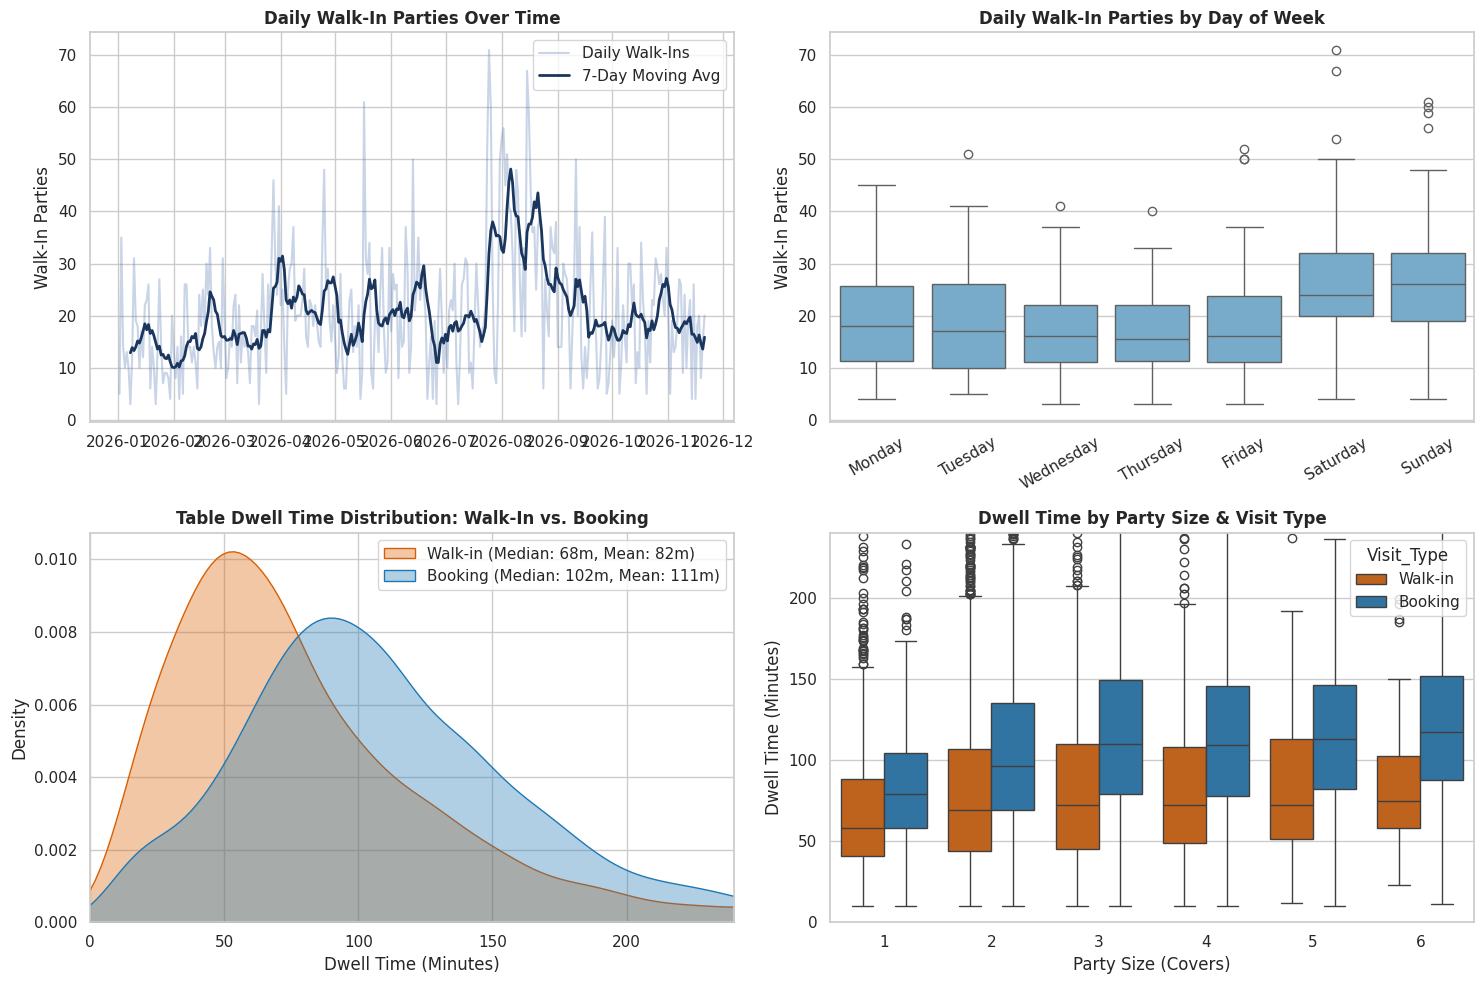

In [24]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Daily Walk-In Parties Over Time
axes[0, 0].plot(daily_walkins['Date'], daily_walkins['walkin_parties'], alpha=0.3, color='#4C72B0', label='Daily Walk-Ins')
axes[0, 0].plot(daily_walkins['Date'], daily_walkins['walkin_parties'].rolling(7).mean(), color='#1B365D', linewidth=2, label='7-Day Moving Avg')
axes[0, 0].set_title('Daily Walk-In Parties Over Time', fontweight='bold')
axes[0, 0].set_ylabel('Walk-In Parties')
axes[0, 0].legend()

# 2. Walk-In Parties by Day of Week
sns.boxplot(
    data=daily_walkins, x='Day_of_Week', y='walkin_parties',
    order=day_order, color='#6BAED6', ax=axes[0, 1]
)
axes[0, 1].set_title('Daily Walk-In Parties by Day of Week', fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Walk-In Parties')
axes[0, 1].tick_params(axis='x', rotation=30)

# 3. Dwell Time Density: Walk-In vs Booking
for v_type, color in [('Walk-in', '#D95F02'), ('Booking', '#1F78B4')]:
    subset = observed_df[observed_df['Visit_Type'] == v_type]['dwell_minutes']
    sns.kdeplot(
        subset, fill=True, alpha=0.35, color=color,
        label=f"{v_type} (Median: {subset.median():.0f}m, Mean: {subset.mean():.0f}m)",
        ax=axes[1, 0]
    )
axes[1, 0].set_title('Table Dwell Time Distribution: Walk-In vs. Booking', fontweight='bold')
axes[1, 0].set_xlabel('Dwell Time (Minutes)')
axes[1, 0].set_xlim(0, 240)
axes[1, 0].legend()

# 4. Dwell Time by Party Size (1–6 Guests)
sns.boxplot(
    data=observed_df[observed_df['Size'].between(1, 6)],
    x='Size', y='dwell_minutes', hue='Visit_Type',
    palette={'Walk-in': '#D95F02', 'Booking': '#1F78B4'},
    ax=axes[1, 1]
)
axes[1, 1].set_title('Dwell Time by Party Size & Visit Type', fontweight='bold')
axes[1, 1].set_xlabel('Party Size (Covers)')
axes[1, 1].set_ylabel('Dwell Time (Minutes)')
axes[1, 1].set_ylim(0, 240)

plt.tight_layout()
plt.show()

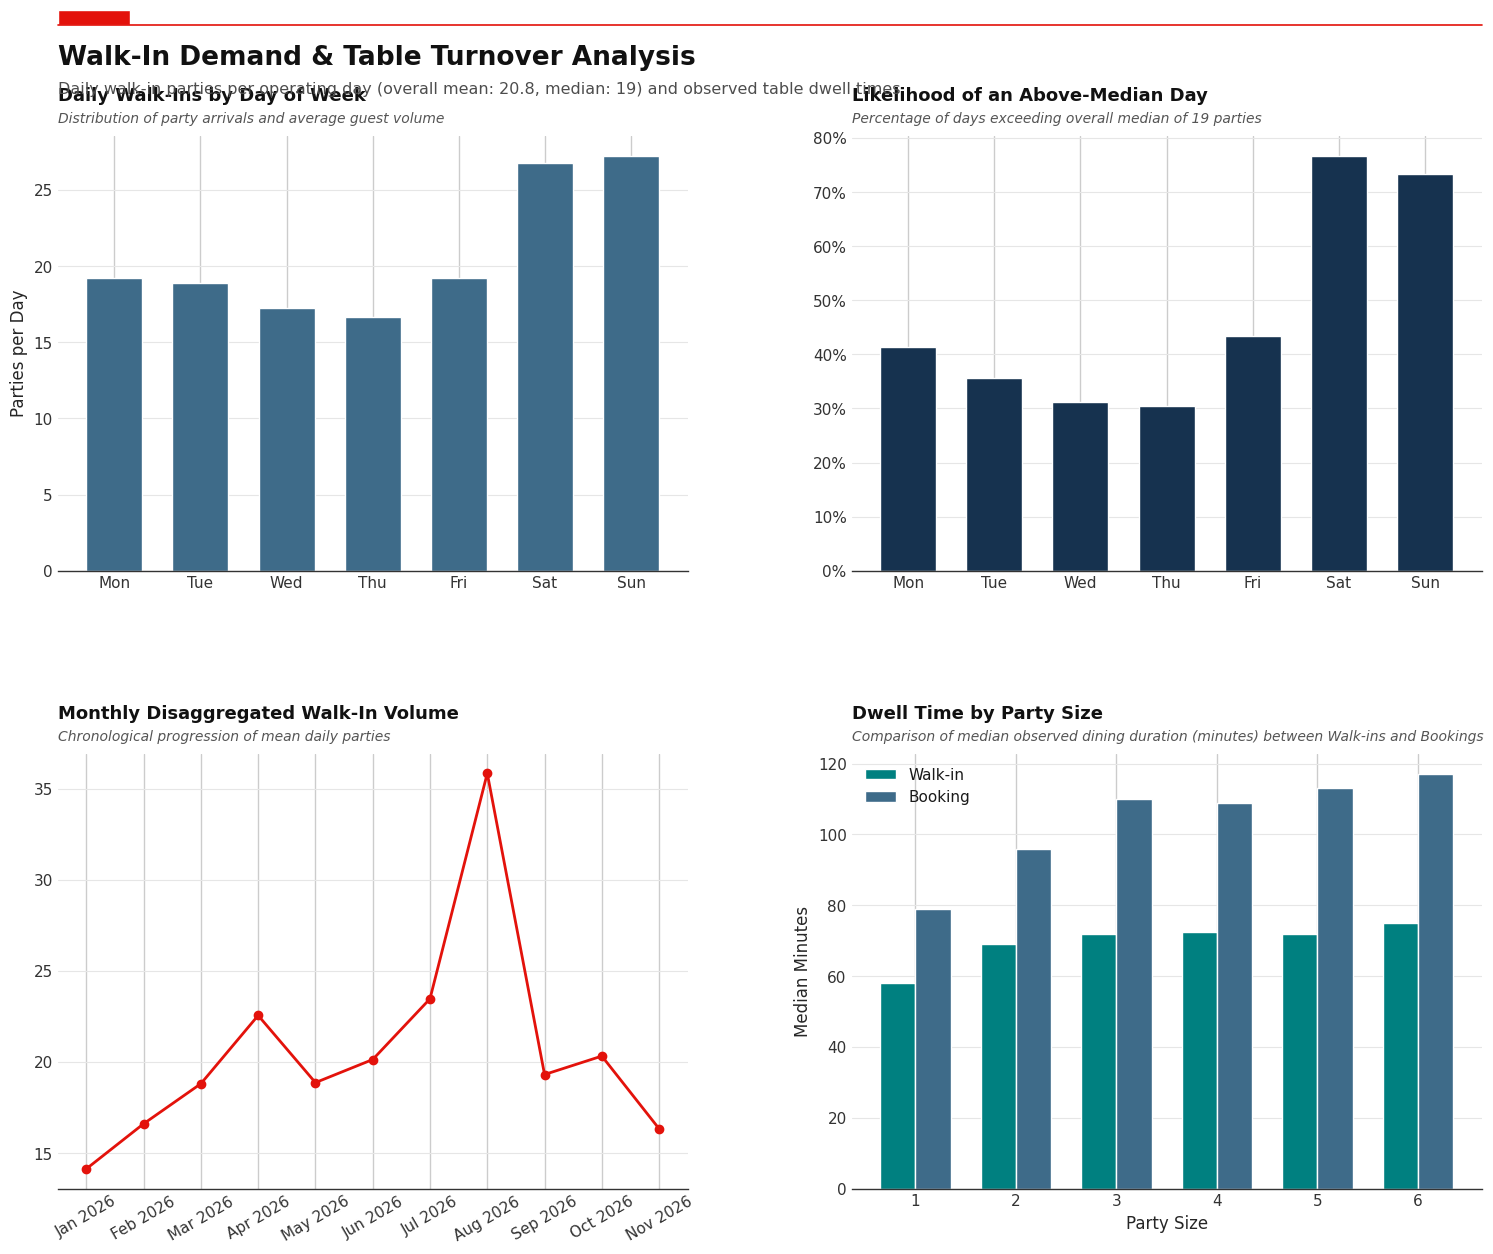

In [28]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as patches
import numpy as np
import pandas as pd

# --- 1. Prepare Aggregated Data ---
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_short = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

# Ensure proper chronological month sorting and readable labels (e.g., 'May 2026')
daily_walkins['Month_Period'] = daily_walkins['Date'].dt.to_period('M')
daily_walkins['Month_Label'] = daily_walkins['Date'].dt.strftime('%b %Y')

overall_median = daily_walkins['walkin_parties'].median()
overall_mean = daily_walkins['walkin_parties'].mean()

# A. Day-of-Week Stats + Probability of an Above-Median Day
dow_stats = (
    daily_walkins.groupby('Day_of_Week')
    .agg(
        mean_parties=('walkin_parties', 'mean'),
        median_parties=('walkin_parties', 'median'),
        q25=('walkin_parties', lambda x: x.quantile(0.25)),
        q75=('walkin_parties', lambda x: x.quantile(0.75)),
        prob_above_med=('walkin_parties', lambda x: (x > overall_median).mean() * 100),
        mean_guests=('walkin_guests', 'mean')
    )
    .reindex(day_order)
)

# B. Monthly Disaggregation (Chronological)
monthly_stats = (
    daily_walkins.groupby(['Month_Period', 'Month_Label'])
    .agg(
        open_days=('Date', 'count'),
        mean_parties=('walkin_parties', 'mean'),
        median_parties=('walkin_parties', 'median'),
        q25=('walkin_parties', lambda x: x.quantile(0.25)),
        q75=('walkin_parties', lambda x: x.quantile(0.75)),
        mean_guests=('walkin_guests', 'mean')
    )
    .reset_index()
    .sort_values('Month_Period')
)

# C. Month x Day-of-Week Matrix (Mean Walk-In Parties per Operating Day)
month_order_labels = monthly_stats['Month_Label'].tolist()
heatmap_data = (
    daily_walkins.pivot_table(
        index='Month_Label',
        columns='Day_of_Week',
        values='walkin_parties',
        aggfunc='mean'
    )
    .reindex(index=month_order_labels, columns=day_order)
)

# D. Dwell Duration by Party Size (1 to 6) - Observed Only
dwell_size = (
    observed_df[observed_df['Size'].between(1, 6)]
    .groupby(['Size', 'Visit_Type'])['dwell_minutes']
    .agg(
        median='median',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        count='count'
    )
    .unstack()
)

# --- 2. Configure The Economist / Pew Research Aesthetic ---
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.8,
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'text.color': '#1A1A1A'
})

ECON_RED = '#E3120B'
NAVY = '#16324F'
SLATE_BLUE = '#3E6B89'
TEAL = '#008080'
MUTED_GREY = '#8C969E'
LIGHT_GRID = '#E6E6E6'

fig = plt.figure(figsize=(16, 13), facecolor='white')
gs = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.26, top=0.88, bottom=0.07, left=0.07, right=0.96)

# Signature Economist Top Accent Bar & Header
fig.add_artist(patches.Rectangle((0.07, 0.965), 0.045, 0.012, facecolor=ECON_RED, transform=fig.transFigure, clip_on=False))
fig.add_artist(plt.Line2D([0.07, 0.96], [0.965, 0.965], color=ECON_RED, linewidth=1.2, transform=fig.transFigure))

fig.text(0.07, 0.935, 'Walk-In Demand & Table Turnover Analysis', fontsize=19, fontweight='bold', color='#111111')
fig.text(
    0.07, 0.912,
    f'Daily walk-in parties per operating day (overall mean: {overall_mean:.1f}, median: {overall_median:.0f}) and observed table dwell times',
    fontsize=11.5, color='#4D4D4D'
)

def style_econ_axis(ax, title, subtitle):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#333333')
    ax.spines['bottom'].set_linewidth(1.0)
    ax.tick_params(axis='both', which='both', length=0)
    ax.grid(axis='y', color=LIGHT_GRID, linestyle='-', linewidth=0.8)
    ax.set_axisbelow(True)
    if title:
        ax.text(0, 1.08, title, transform=ax.transAxes, fontsize=13, fontweight='bold', color='#111111', ha='left')
    if subtitle:
        ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10, style='italic', color='#555555', ha='left')

# Define axes and plot
ax1 = fig.add_subplot(gs[0, 0])
style_econ_axis(ax1, "Daily Walk-Ins by Day of Week", "Distribution of party arrivals and average guest volume")
ax1.bar(day_short, dow_stats['mean_parties'], color=SLATE_BLUE, width=0.65, label='Mean Parties')
ax1.set_ylabel('Parties per Day')

ax2 = fig.add_subplot(gs[0, 1])
style_econ_axis(ax2, "Likelihood of an Above-Median Day", "Percentage of days exceeding overall median of " + f"{overall_median:.0f} parties")
ax2.bar(day_short, dow_stats['prob_above_med'], color=NAVY, width=0.65)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())

ax3 = fig.add_subplot(gs[1, 0])
style_econ_axis(ax3, "Monthly Disaggregated Walk-In Volume", "Chronological progression of mean daily parties")
ax3.plot(monthly_stats['Month_Label'], monthly_stats['mean_parties'], marker='o', color=ECON_RED, linewidth=2)
ax3.tick_params(axis='x', rotation=30)

ax4 = fig.add_subplot(gs[1, 1])
style_econ_axis(ax4, "Dwell Time by Party Size", "Comparison of median observed dining duration (minutes) between Walk-ins and Bookings")
x_indices = np.arange(1, 7)
width = 0.35
ax4.bar(x_indices - width/2, dwell_size['median']['Walk-in'], width, label='Walk-in', color=TEAL)
ax4.bar(x_indices + width/2, dwell_size['median']['Booking'], width, label='Booking', color=SLATE_BLUE)
ax4.set_xlabel('Party Size')
ax4.set_ylabel('Median Minutes')
ax4.set_xticks(x_indices)
ax4.legend(loc='upper left', frameon=False)

plt.show()